# High-risk Project code: testing pirfenidone for pattern hair loss with an audited LLM evidence agent
**Brian Ellis · A I 380H AI in Healthcare · Fall 2026**

### AI disclosure
I wrote and tested the code together with Claude (Opus 5.5), and it also helped me come up with ideas and draft this
notebook. The question and the calls on where to take it were mine, and I went through the results myself before
anything went in. The evidence agent itself runs on Llama 3.3 70B, DeepSeek V3.1, Gemini 2.5 Flash and GPT-4o-mini
through OpenRouter.

### What this notebook does
The analysis is 15 numbered scripts in `analysis/`, one per research track, plus shared loaders in `src/`. This notebook
walks through them in order. For each track it states the question, prints the core code straight from the script, and
shows the saved results and the report figure. Three results are recomputed live from the intermediate tables (the FDA
comparator ratio, the evidence agent's grades and the dose arithmetic), to show the saved numbers come from the code.

It doesn't re-query the live APIs. PubMed counts drift as papers are added, so a live re-query would no longer match the
report. To rebuild everything from public downloads, run `analysis/run_all.sh` (about 10 minutes, needs internet). The
evidence agent replays every LLM reply from its cache, so a rebuild needs no API key.

| Path | What's there |
|---|---|
| `analysis/00_download_data.sh` | Downloads all public data into `data/` |
| `analysis/01_*.py` to `15_*.py` | One script per track (A to N), then the report figures |
| `src/signatures.py`, `src/drug_scoring.py` | GEO loaders, differential expression, drug scoring |
| `data/llm_agent/` | The frozen PubMed set and every cached LLM reply |
| `results/` | Tables, plus `NN_summary.json` with each track's key numbers |
| `figs/report/` | The nine report figures |

Environment: conda env `394_HW1` (Python 3.11, numpy 1.26, pandas, scipy, statsmodels, scikit-learn, pysam, matplotlib).

In [1]:
import ast, hashlib, json, pathlib, platform, runpy, sys
import numpy as np, pandas as pd, scipy
from IPython.display import Image, display

ROOT = pathlib.Path.cwd()
RESULTS, FIGS = ROOT / "results", ROOT / "figs" / "report"
sys.path.insert(0, str(ROOT / "analysis"))
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 70)


def show_code(path, names):
    src = (ROOT / path).read_text()
    for node in ast.parse(src).body:
        name = getattr(node, "name", None)
        if name is None and isinstance(node, ast.Assign):
            name = getattr(node.targets[0], "id", None)
        if name in names:
            print(ast.get_source_segment(src, node), end="\n\n")


def show_from(path, marker):
    lines = (ROOT / path).read_text().splitlines()
    start = next(i for i, l in enumerate(lines) if l.startswith(marker))
    print("\n".join(lines[start:]))


def summary(n):
    return json.load(open(RESULTS / f"{n}_summary.json"))


def fig(name, width=900):
    display(Image(filename=str(FIGS / f"{name}.png"), width=width))


print("python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__, "| scipy", scipy.__version__)

python 3.11.13 | numpy 1.26.4 | pandas 2.3.3 | scipy 1.17.1


## A. Is there a reproducible bald-scalp signature?
Two independent studies compare bald with haired scalp: GSE36169 (5 men, paired biopsies) and GSE90594 (14 AGA vs 14
healthy). They are combined into one consensus signature (Stouffer z), keeping only genes that move the same way in both.

In [2]:
show_code("analysis/common.py", ["consensus_bald_signature"])
s = summary("01")
a = s["agreement"]["GSE36169 vs GSE90594"]
print(f"Agreement between the two in-vivo studies: rho {a['rho_sig_either']:.2f}; {a['same_direction']} of {a['both_sig']} genes significant in both move the same way")
print(f"Consensus signature: {s['consensus_genes']:,} genes")

def consensus_bald_signature():
    """Stouffer-combined bald-scalp signature from GSE36169 (5 paired men) and GSE90594 (14 AGA vs 14 healthy),
    keeping genes that move the same direction in both."""
    b1 = S.bald_vs_haired().rename(columns={"lfc_bald": "lfc", "p_bald": "p"})
    b3 = S.alopecia_vs_healthy()
    inv = b1.join(b3, lsuffix="_g", rsuffix="_m", how="inner")
    inv = inv[np.sign(inv.lfc_g) == np.sign(inv.lfc_m)].copy()
    inv["z"] = (np.sign(inv.lfc_g) * stats.norm.isf(inv.p_g / 2) + np.sign(inv.lfc_m) * stats.norm.isf(inv.p_m / 2)) / np.sqrt(2)
    return inv

Agreement between the two in-vivo studies: rho 0.72; 406 of 415 genes significant in both move the same way
Consensus signature: 3,789 genes


## B. Does drug-signature screening pass its own calibration?
Every drug in LINCS L1000 and the original Connectivity Map is scored on how strongly it reverses the bald-scalp or
DHT-response signature. The check: do drugs known to grow hair (from SIDER side effects) rank above drugs known to cause
hair loss? It fails, so signature screening is reported as a negative result.

def reversal_z(sig_up, sig_dn, drug_up, drug_dn, universe):
    sig_up, sig_dn = sig_up & universe, sig_dn & universe
    drug_up, drug_dn = drug_up & universe, drug_dn & universe
    n = len(universe)
    pairs_rev = [(sig_up, drug_dn), (sig_dn, drug_up)]
    pairs_mim = [(sig_up, drug_up), (sig_dn, drug_dn)]
    obs = sum(len(a & b) for a, b in pairs_rev) - sum(len(a & b) for a, b in pairs_mim)
    exp_each = [len(a) * len(b) / n for a, b in pairs_rev + pairs_mim]
    var = sum(e * (1 - e / max(len(a), 1)) for e, (a, b) in zip(exp_each, pairs_rev + pairs_mim))
    exp = sum(exp_each[:2]) - sum(exp_each[2:])
    return (obs - exp) / np.sqrt(max(var, 1e-9))

def calibration(scores, labels, n_perm=10000, seed=0):
    df = scores[scores.key.isin(labels)].copy()
    df["y"] = df.key.map(labels)
    if df.y.nunique() < 2:
        return None
    from sklearn.metrics import roc_auc_score
    auc = roc_auc_score(df.y, df.z)
    rng = np.random.default_rng(seed)
    perm = np.array([roc_auc_s

,library,signature,drugs,n_growth,n_loss,auroc,p_perm
0,lincs,invivo_100,5398,21.0,300.0,0.539,0.261
1,lincs,dht_100,5398,21.0,300.0,0.630,0.021
2,lincs,invivo_200,5398,21.0,300.0,0.510,0.459
3,lincs,dht_200,5398,21.0,300.0,0.596,0.076
4,cmap,invivo_100,1308,12.0,142.0,0.651,0.050
5,cmap,dht_100,1308,12.0,142.0,0.342,0.972
6,cmap,invivo_200,1308,12.0,142.0,0.664,0.030
7,cmap,dht_200,1308,12.0,142.0,0.320,0.980


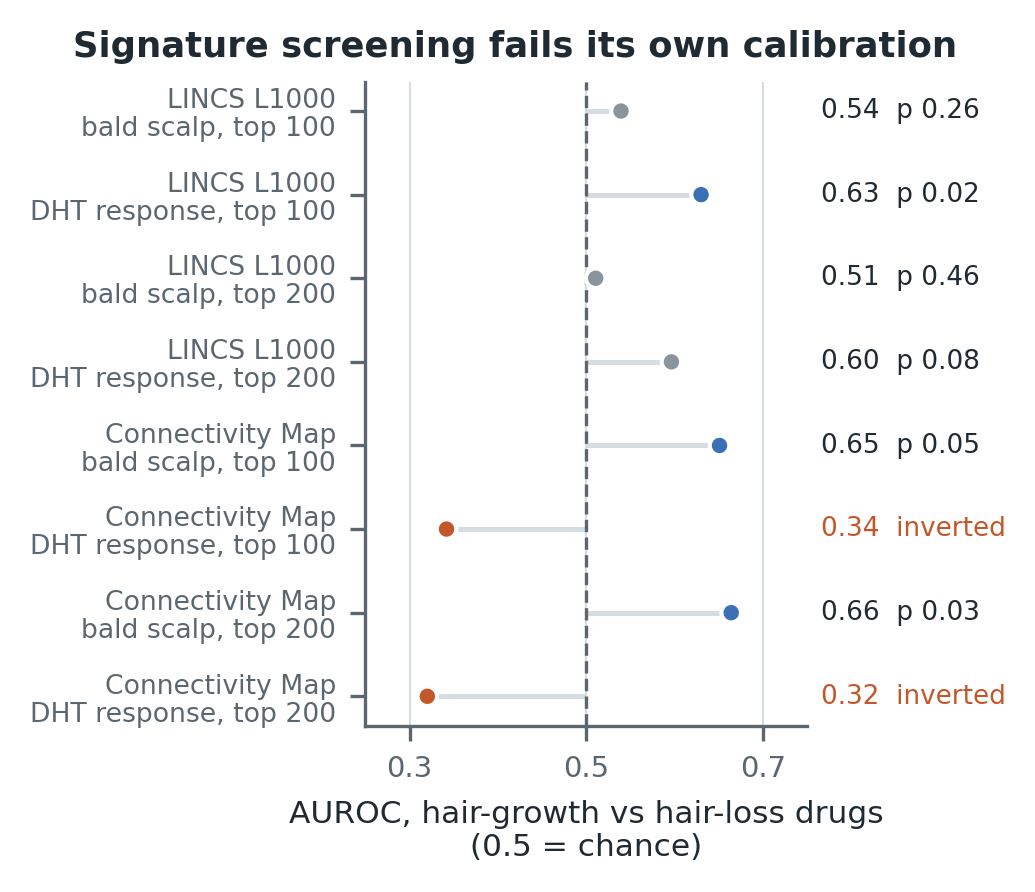

In [3]:
show_code("src/drug_scoring.py", ["reversal_z", "calibration"])
cal = pd.read_csv(RESULTS / "02_calibration.csv").dropna(subset=["auroc"])
display(cal[["library", "signature", "drugs", "n_growth", "n_loss", "auroc", "p_perm"]].round(3))
fig("fig2_calibration", 480)

## C. Which genes carry the genetic risk, and can any drug act on them?
Open Targets lists every gene with evidence for androgenetic alopecia; we count how many strong genetic hits have any drug.

In [4]:
s = summary("03")
print(f"Associated targets: {s['associated_targets']:,}; genetic score >= 0.5: {s['genetic_ge_0.5']}; with any drug or candidate: {s['with_any_drug']}; with an approved drug: {s['with_approved_drug']}")
for t in s["approved_drug_targets"]:
    print(f"  {t['symbol']:7} {t['approved_drugs'][:90]}")

Associated targets: 1,039; genetic score >= 0.5: 142; with any drug or candidate: 12; with an approved drug: 5
  HDAC9   BELINOSTAT;ENTINOSTAT;GIVINOSTAT;GIVINOSTAT HYDROCHLORIDE;PANOBINOSTAT;PANOBINOSTAT LACTAT
  BCL2    NAVITOCLAX;OBLIMERSEN;VENETOCLAX
  AR      ABIRATERONE;APALUTAMIDE;BICALUTAMIDE;CLASCOTERONE;DANAZOL;DAROLUTAMIDE;ENZALUTAMIDE;ETHYLE
  SRD5A2  ABIRATERONE;DUTASTERIDE;FINASTERIDE
  TGFB1   LUSPATERCEPT


## D. Is there a scarring program in bald scalp, and is it just lost follicles?
Bald-up genes are tested against the MSigDB Hallmark sets. Then, in GSE90594, each scarring and immune gene is refit with
a follicle-content score as a covariate, so a gene can't look raised just because the biopsy holds more dermis.

FOLLICLE = ["KRT25", "KRT27", "KRT71", "KRT72", "KRT73", "TCHH", "KRT31", "KRT32", "KRT33A", "KRT33B", "KRT35", "KRT85",
            "KRT86", "LHX2", "MSX2", "HOXC13", "KRT75", "DSG4"]
FIB = ["COL1A1", "COL1A2", "COL3A1", "SPARC", "FBLN1", "FBLN2", "FBLN5", "TIMP1", "PDGFRB", "DCN", "LOX", "TGFBI", "FN1",
       "ACTA2", "VIM", "S100A4", "LUM", "POSTN", "TWIST1", "TGFB1", "SERPINE1", "CCN2"]
IMM = ["CD74", "HLA-DRA", "HLA-DRB1", "HLA-DMA", "C1S", "C1R", "CFH", "VCAM1", "CD3E", "PTPRC", "CCL19"]
expr, meta = S.series_matrix_with_meta(S.GEO / "GSE90594_series_matrix.txt.gz")
expr = S.collapse(expr, S.probe_map("GPL17077"))
bald = (meta["disease state"] == "alopecia").astype(int).values
fol = [g for g in FOLLICLE if g in expr.index]
fscore = expr.loc[fol].sub(expr.loc[fol].mean(axis=1), axis=0).div(expr.loc[fol].std(axis=1), axis=0).mean().values
rows = []
for g in [x for x in FIB + IMM if x in expr.index]:
    y = expr.loc[g].values
    m0 = sm.OLS(y, sm.add_constant(bald)).fit()
    m1 

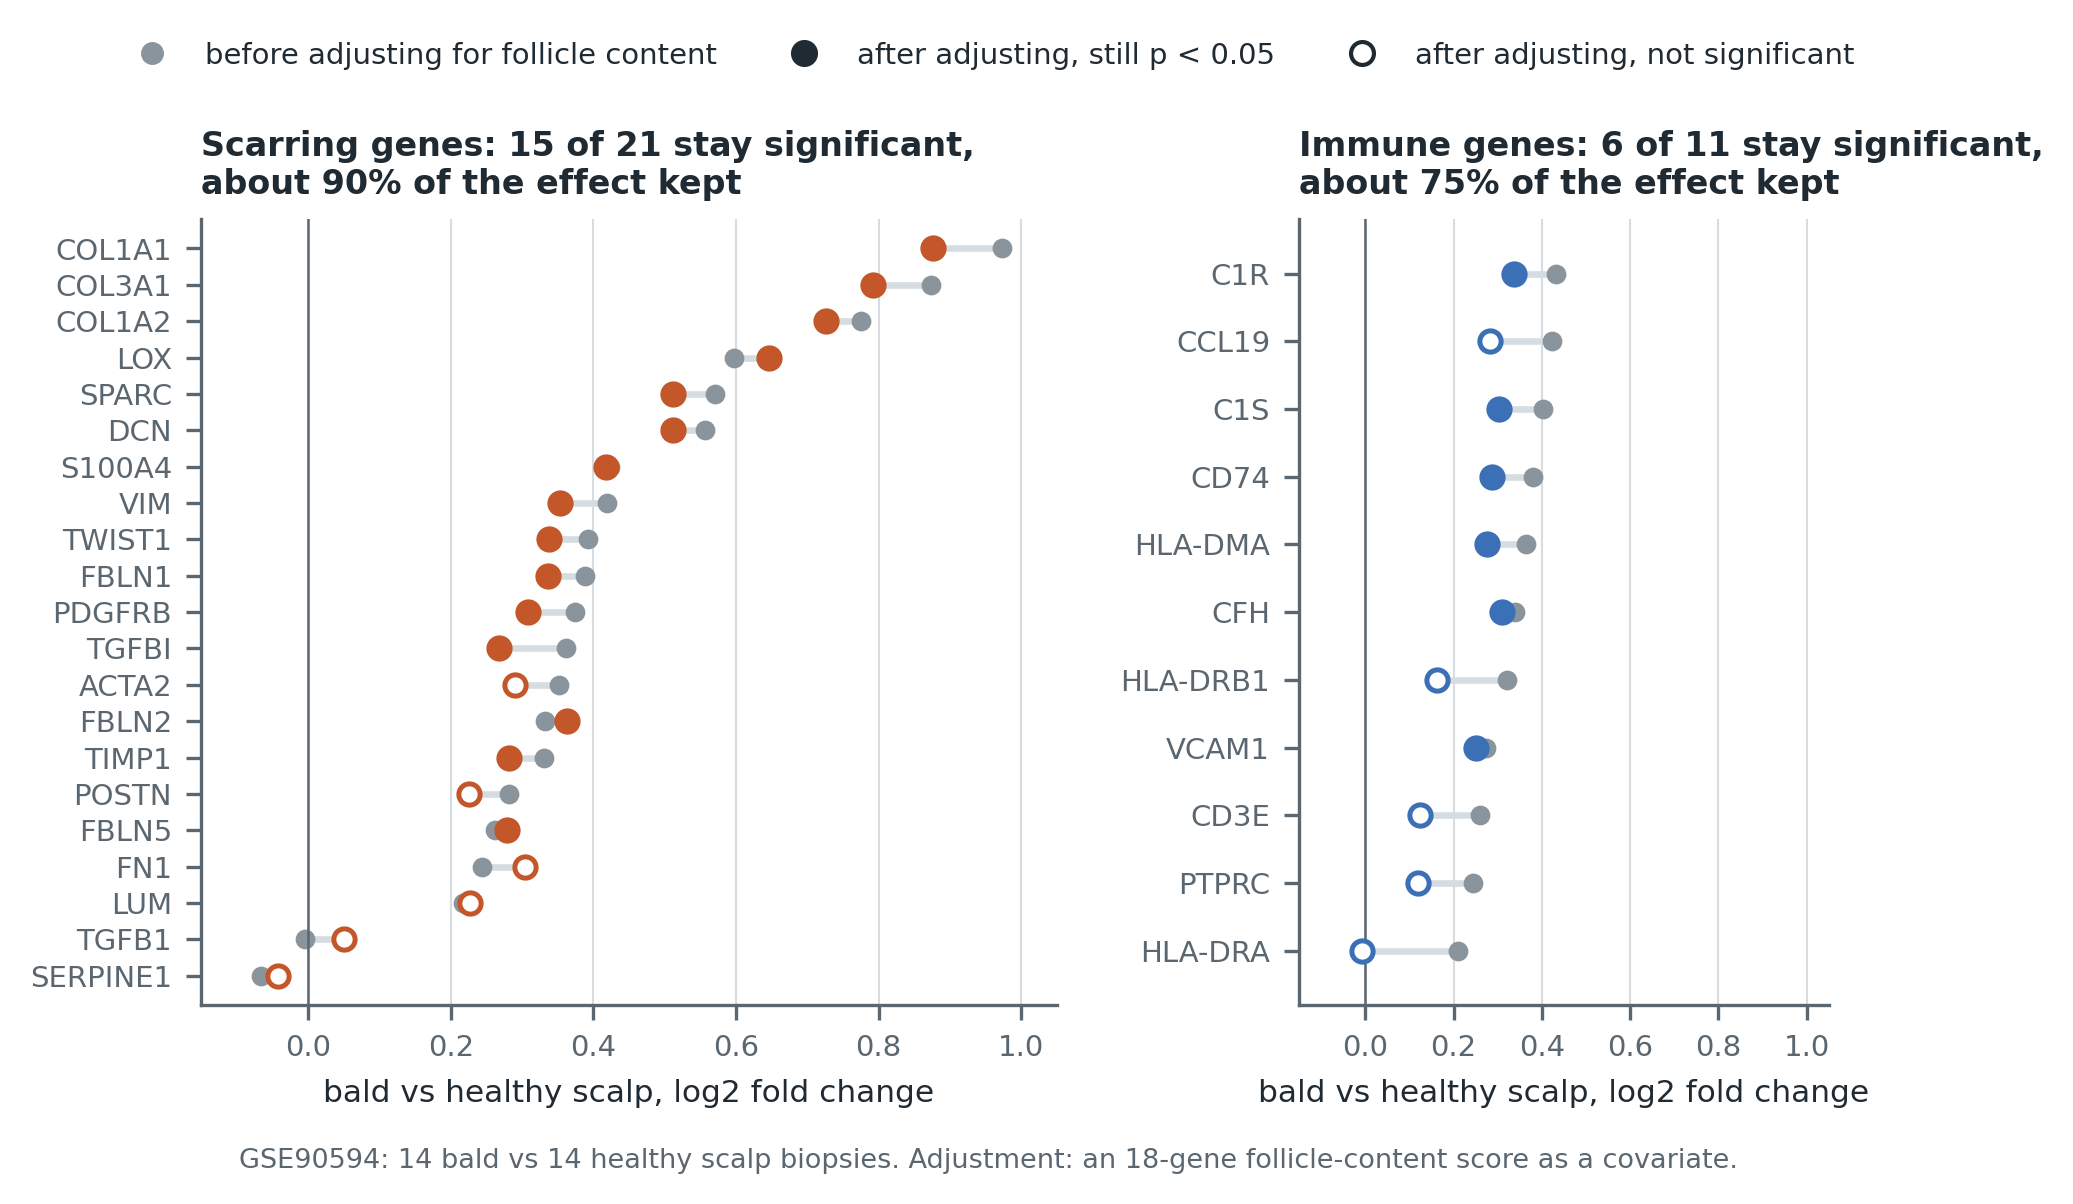

In [5]:
show_from("analysis/04_fibrosis_program.py", "FOLLICLE = ")
s = summary("04")
print("\nTop Hallmark sets among bald-up genes:")
for r in s["hallmark_top"]["bald_up"][:3]:
    print(f"  {r['term']:38} adjusted p {r['adj_p']:.1e} ({r['n_genes']} genes)")
for k, v in s["composition_GSE90594"].items():
    print(f"{k}: {v['sig_adjusted']} of {v['genes']} genes stay significant after adjustment, median effect kept {v['median_effect_kept']:.0%}")
fig("fig3_scarring_program")

## E. Is part of the program TGF-beta driven, and does pirfenidone switch it off?
TGF-beta-induced genes in lung fibroblasts (GSE178518) are intersected with bald-up genes. Then the drugs' effects on those
genes are measured: pirfenidone at 0.11 mM, nintedanib and saracatinib (GSE178518), and pirfenidone at 1 mM (GSE226249).

"""Track E: is part of the bald-scalp program TGF-beta-driven, and does pirfenidone switch it off in human fibroblasts?
GSE178518: lung fibroblasts +/- TGF-beta with pirfenidone (20 ug/mL, about 0.1 mM), nintedanib or saracatinib.
GSE226249: lung fibroblasts from 3 donors, serum-activated, +/- pirfenidone 1 mM."""
import numpy as np
import pandas as pd
from scipy import stats

from common import RESULTS, S, consensus_bald_signature, save_summary

inv = consensus_bald_signature()
fib, sizes = S.tgfb_and_antifibrotics()
sr = S.pirfenidone_serum_fibroblasts()
tg = fib["tgfb"]
up200 = set(inv[inv.z > 0].nlargest(200, "z").index)
universe = set(inv.index) & set(tg.index)
tg_up = set(tg[(tg.p < .05) & (tg.lfc > .5)].index) & universe
a = len(up200 & tg_up); b = len((up200 & universe) - tg_up); c = len(tg_up - up200); d = len(universe - up200 - tg_up)
odds, p = stats.fisher_exact([[a, b], [c, d]], alternative="greater")
driven = sorted(up200 & tg_up)
print(f"bald-up genes that TGF-beta induce

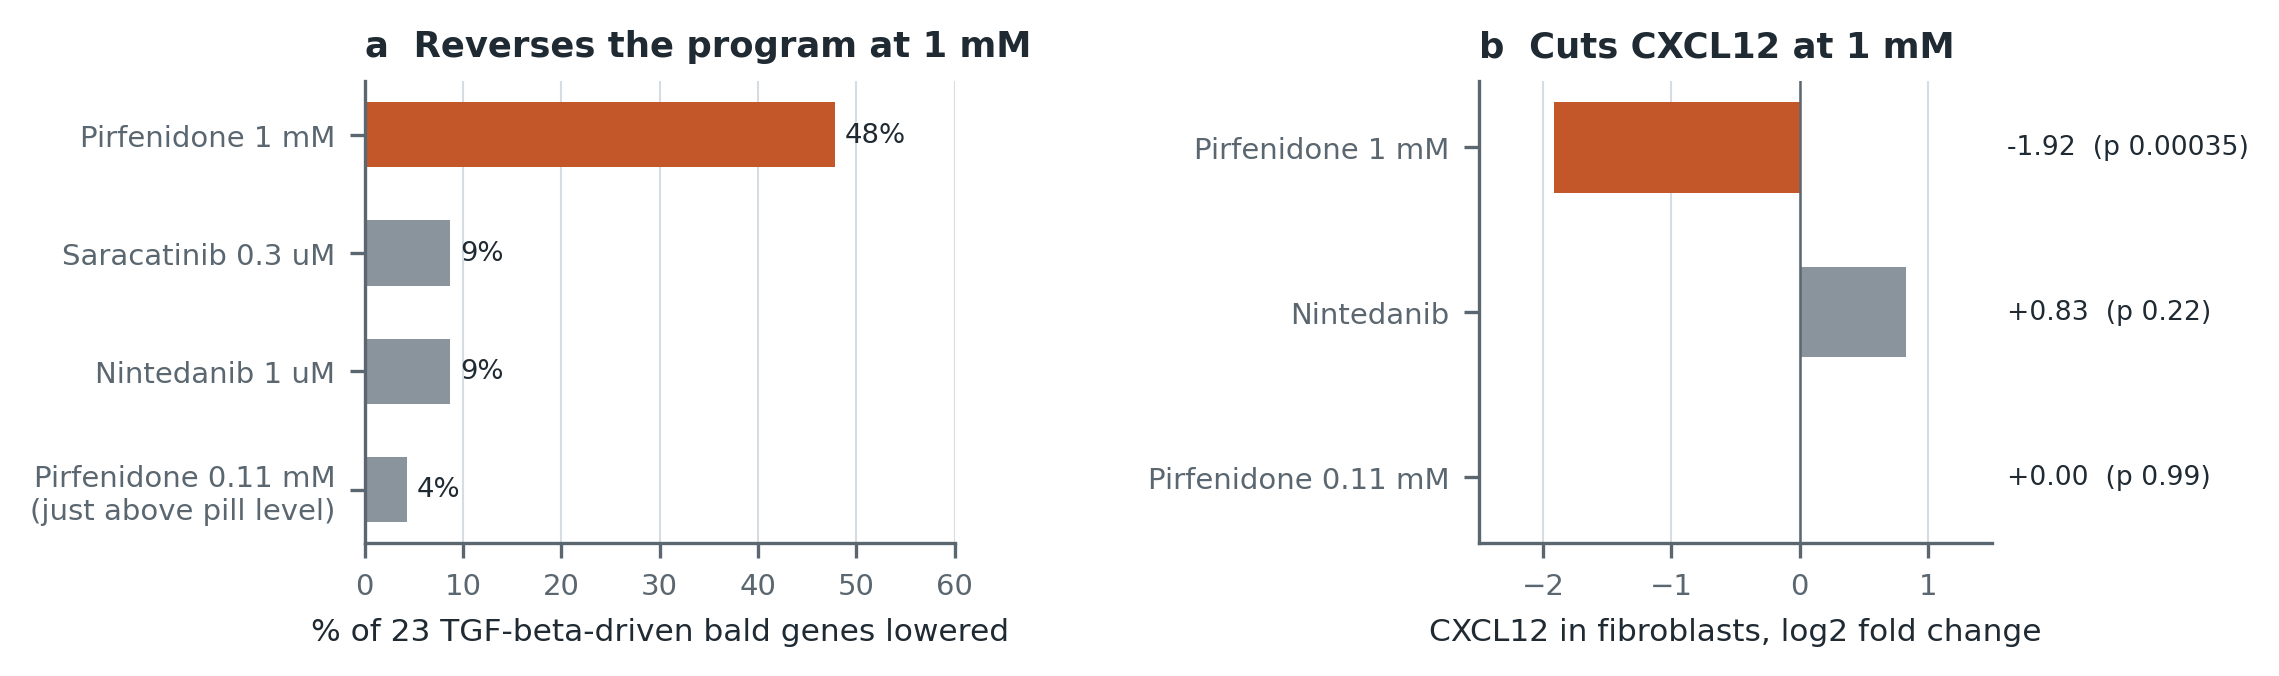

In [6]:
print((ROOT / "analysis/05_tgfb_fibroblasts_pirfenidone.py").read_text())
s = summary("05")
e = s["tgfb_enrichment"]
print(f"TGF-beta-driven bald genes: {e['overlap']} of {e['bald_up_tested']} (odds ratio {e['odds_ratio']:.1f}, p {e['p']:.1e})")
for k, v in s["drugs"].items():
    print(f"  {k:28} lowers {v['driven_lowered_sig']:.0%} of them (median log2 change {v['driven_median_change']:+.2f})")
fig("fig4_pirfenidone_fibroblasts")

## F. Real-world reports: FDA adverse events
Reporting odds ratios from openFDA, first on drugs with known hair effects (calibration), then pirfenidone against
nintedanib, the other drug for the same lung disease. **Live check:** the comparator ratio is recomputed below from the saved
report counts with the same formula the script uses.

def ror(a, n_drug, n_event, n_all):
    b, c = n_drug - a, n_event - a
    d = n_all - n_drug - c
    if min(a, b, c, d) <= 0:
        return float("nan"), float("nan"), float("nan")
    r = (a / b) / (c / d)
    se = math.sqrt(1 / a + 1 / b + 1 / c + 1 / d)
    return r, math.exp(math.log(r) - 1.96 * se), math.exp(math.log(r) + 1.96 * se)



,stratum,pirf_alopecia,pirf_reports,nint_alopecia,nint_reports,ratio,recomputed,lo95,hi95
0,all,122,40482,317,31339,0.296,0.296,0.240,0.365
1,men,26,24421,69,16161,0.249,0.249,0.158,0.390
2,women,94,14244,240,11538,0.313,0.313,0.246,0.397
3,age_60_85,48,15790,207,16381,0.238,0.238,0.174,0.326


recomputed ratios match the saved ones: True


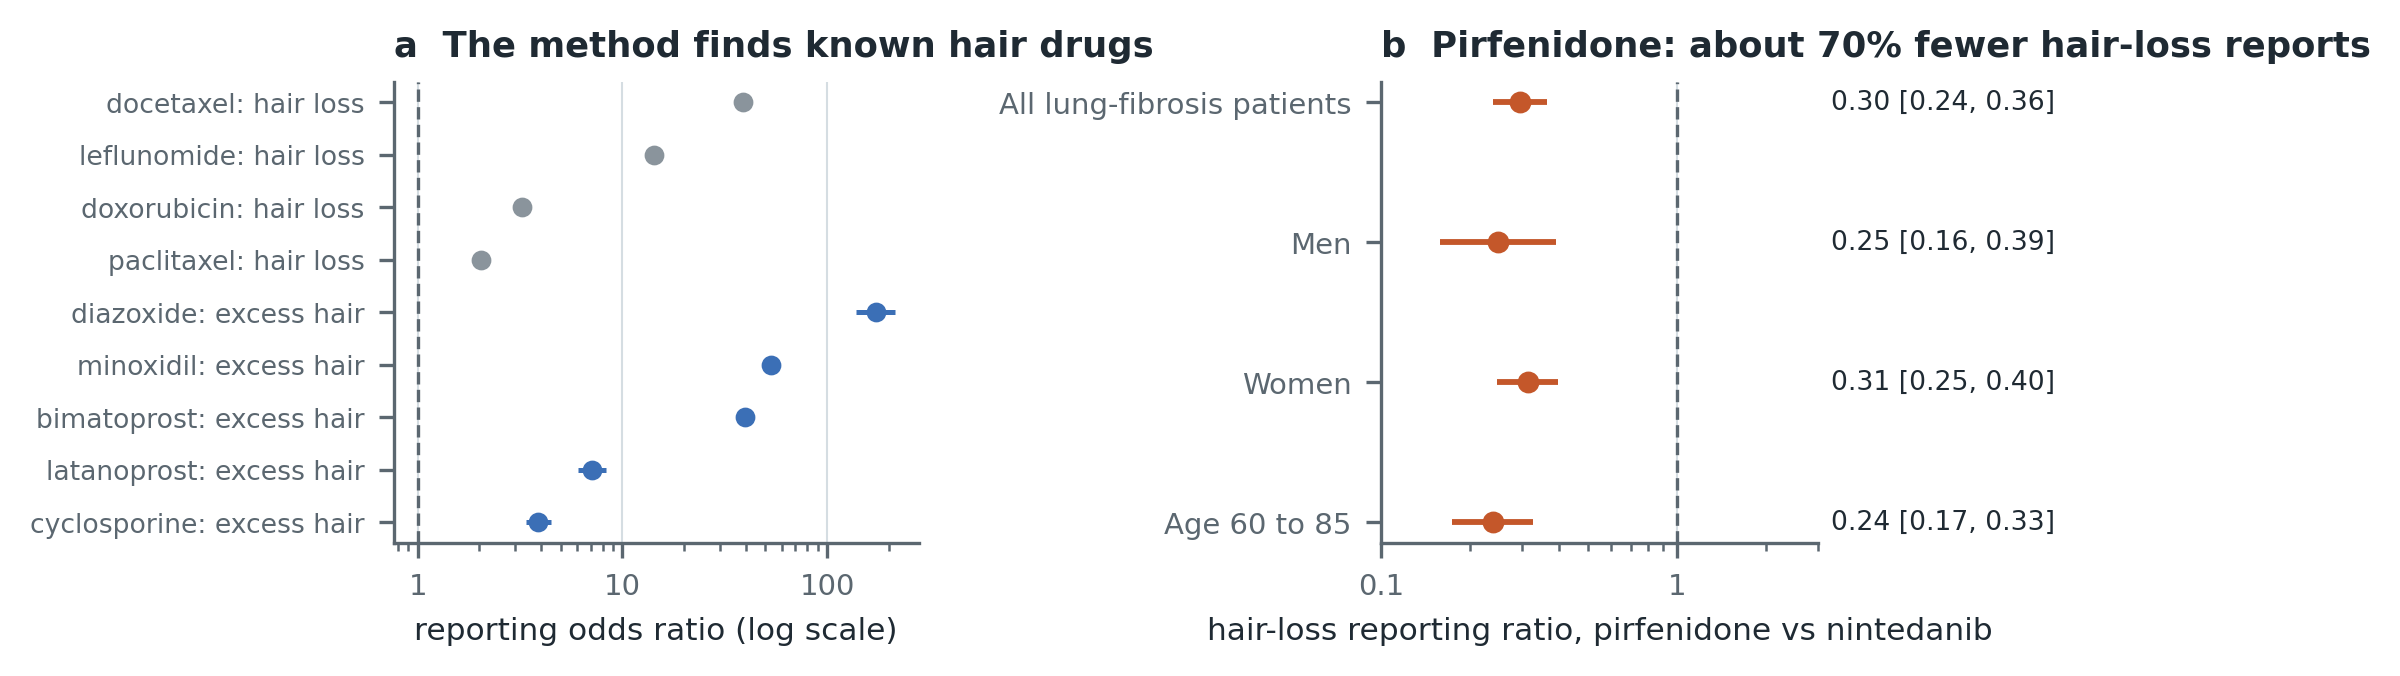

In [7]:
show_code("analysis/06_faers.py", ["ror"])
comp = pd.read_csv(RESULTS / "06_faers_pirfenidone_vs_nintedanib.csv")
r = (comp.pirf_alopecia / (comp.pirf_reports - comp.pirf_alopecia)) / (comp.nint_alopecia / (comp.nint_reports - comp.nint_alopecia))
se = np.sqrt(1 / comp.pirf_alopecia + 1 / (comp.pirf_reports - comp.pirf_alopecia) + 1 / comp.nint_alopecia + 1 / (comp.nint_reports - comp.nint_alopecia))
comp["recomputed"] = r
comp["lo95"], comp["hi95"] = np.exp(np.log(r) - 1.96 * se), np.exp(np.log(r) + 1.96 * se)
display(comp[["stratum", "pirf_alopecia", "pirf_reports", "nint_alopecia", "nint_reports", "ratio", "recomputed", "lo95", "hi95"]].round(3))
print("recomputed ratios match the saved ones:", bool(np.allclose(comp.ratio, comp.recomputed)))
fig("fig6_faers")

## G. Has anyone tested this already?
PubMed and ClinicalTrials.gov counts per candidate drug and per mechanism (saved on the day they were queried).

In [8]:
s = summary("07")
display(pd.DataFrame(s["drugs"])[["group", "drug", "pattern_hair_loss_papers", "hair_papers", "all_papers"]])
print(s["mechanism_papers"])

,group,drug,pattern_hair_loss_papers,hair_papers,all_papers
0,TGF-beta / scarring,pirfenidone,0,0,2589
1,TGF-beta / scarring,telmisartan,0,0,2990
2,TGF-beta / scarring,losartan,0,1,10193
3,TGF-beta / scarring,tranilast,0,0,772
4,TGF-beta / scarring,nintedanib,0,3,2437
5,TGF-beta / scarring,galunisertib,0,1,210
6,IL-6,tocilizumab,0,11,8284
7,IL-6,tofacitinib,3,340,4445
8,IL-6,ruxolitinib,4,112,4125
9,IL-6,baricitinib,5,363,2453


{'fibrosis + pattern hair loss': 214, 'TGF-beta + pattern hair loss': 78, 'TGF-beta + catagen': 81, 'pirfenidone + skin/scar/topical': 200}


## H. Which scalp cells carry the program?
Using the authors' pseudobulk expression for 41 annotated clusters of the Ober-Reynolds 2023 scalp atlas, each gene set
is scored per cell type against 10,000 expression-matched random gene sets.

def module_scores(z, genes, bins, n_perm=10000, seed=0):
    genes = [g for g in genes if g in z.index]
    obs = z.loc[genes].mean()
    rng = np.random.default_rng(seed)
    pools = {b: np.flatnonzero(bins.values == b) for b in np.unique(bins.values)}
    zv = z.values.astype(np.float32)
    exceed = np.zeros(z.shape[1])
    for chunk in np.array_split(np.arange(n_perm), 10):
        draws = np.stack([rng.choice(pools[bins[g]], len(chunk)) for g in genes], axis=1)
        exceed += (zv[draws].mean(axis=1) >= obs.values).sum(axis=0)
    p = (exceed + 1) / (n_perm + 1)
    return pd.DataFrame({"score": obs, "p": p, "q": multipletests(p, method="fdr_bh")[1]}), genes

TGF-beta-driven bald genes: D.Fib_4 +1.87 (q 0.001), D.Fib_3 +1.69 (q 0.001), D.Sheath +1.65 (q 0.001), D.Papilla +1.43 (q 0.001)
Pirfenidone-lowered (1 mM): D.Fib_4 +1.89 (q 0.002), D.Fib_3 +1.66 (q 0.002), D.Sheath +1.44 (q 0.003), D.Papilla +1.16 (q 0.022)
Hair-loss genetics, all strong (>=0.5): D.Papilla +1.06 (q 0.001)

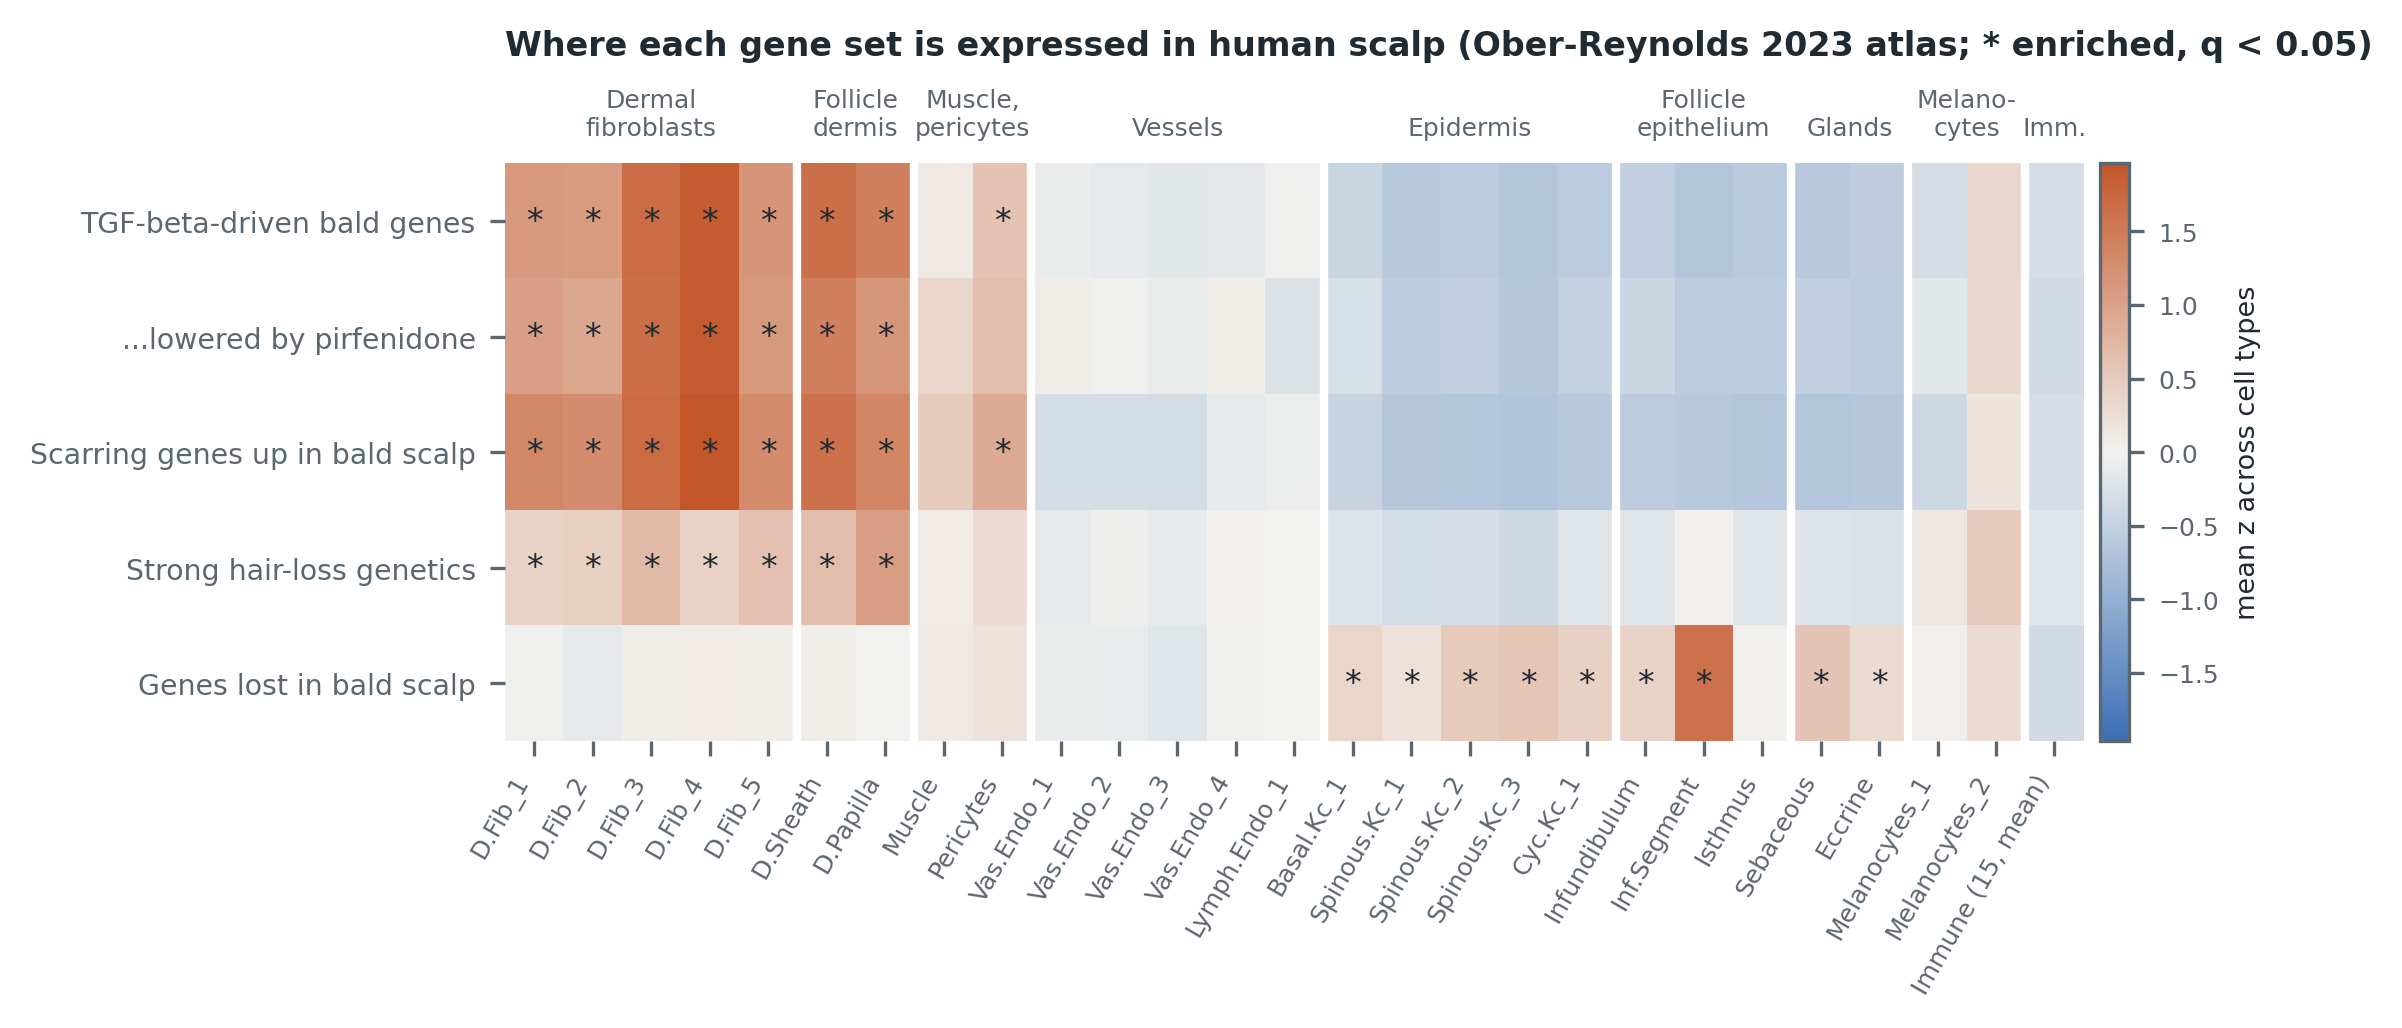

In [9]:
show_code("analysis/08_scalp_cell_localization.py", ["module_scores"])
s = summary("08")
for name in ["TGF-beta-driven bald genes", "Pirfenidone-lowered (1 mM)", "Hair-loss genetics, all strong (>=0.5)"]:
    top = ", ".join(f"{c['cluster']} {c['score']:+.2f} (q {c['q']:.3f})" for c in s["sets"][name]["top_clusters"][:4])
    print(f"{name}: {top}")
fig("fig5_scalp_localization")

## I. The LLM evidence agent
Two reviewer models label every claim-abstract pair independently (stance, evidence type, verbatim quote); a tiebreaker
decides disagreements; grades come from rules fixed in code. **Live check:** the grades are recomputed below from the saved
labels with the script's own `grade` function.

In [10]:
show_code("analysis/09_llm_evidence_agent.py", ["REVIEWERS", "ADJUDICATOR", "SHADOW", "grade"])
src = (ROOT / "analysis/09_llm_evidence_agent.py").read_text()
node = next(n for n in ast.parse(src).body if getattr(n, "name", None) == "grade")
ns = {}
exec(ast.get_source_segment(src, node), ns)
labels = pd.read_csv(RESULTS / "09_evidence_labels.csv")
saved = pd.read_csv(RESULTS / "09_claim_grades.csv", keep_default_na=False).set_index("claim_id")
live = pd.DataFrame({cid: ns["grade"](rows) for cid, rows in labels.groupby("claim_id")}).T
check = saved[["grade", "supporting_primary", "supporting_human", "contradicting"]].join(live[["grade"]], rsuffix="_live")
display(check)
print("live grades match the saved ones:", bool((check.grade == check.grade_live).all()))

REVIEWERS = ["meta-llama/llama-3.3-70b-instruct", "deepseek/deepseek-chat-v3.1"]

ADJUDICATOR = "google/gemini-2.5-flash"

SHADOW = "openai/gpt-4o-mini"

def grade(rows):
    prim = rows[rows.final.isin(["supports", "contradicts", "mixed"]) & ~rows.final_type.isin(["review", "other"])]
    n_sup, n_con, n_mix = (prim.final == "supports").sum(), (prim.final == "contradicts").sum(), (prim.final == "mixed").sum()
    n_hum = ((prim.final == "supports") & prim.final_type.isin(["human_patients_or_tissue", "human_ex_vivo"])).sum()
    n_rev = ((rows.final == "supports") & (rows.final_type == "review")).sum()
    tot = n_sup + n_con + n_mix
    con_share = (n_con + 0.5 * n_mix) / tot if tot else 0.0
    if tot >= 3 and con_share > 1 / 3:
        g = "Contested"
    elif n_sup >= 3 and n_hum >= 1 and con_share <= 0.2:
        g = "Strong"
    elif n_sup >= 2 and con_share <= 1 / 3:
        g = "Moderate"
    elif n_sup >= 1 or n_rev >= 1:
        g = "Weak"
    else:
        g = "None"
    ret

,grade,supporting_primary,supporting_human,contradicting,grade_live
claim_id,,,,,
C1 scarring in bald scalp,Strong,4,2,1,Strong
C2 DHT raises TGF-beta,Strong,26,1,4,Strong
C3 TGF-beta stops hair growth,Strong,36,11,2,Strong
C4 pirfenidone is antifibrotic in skin,Moderate,6,0,0,Moderate
C5 topical pirfenidone is tolerated,Strong,8,3,0,Strong
pirfenidone | antifibrotic in skin,Strong,3,1,0,Strong
pirfenidone | good for hair,Weak,1,0,0,Weak
tranilast | antifibrotic in skin,Strong,16,5,0,Strong
tranilast | good for hair,None,0,0,0,None


live grades match the saved ones: True


,population_weighted,agree_stratum,disagree_stratum,clear_items_only
pipeline,0.893,0.95,0.50,0.821
meta-llama/llama-3.3-70b-instruct,0.931,0.95,0.80,0.929
deepseek/deepseek-chat-v3.1,0.849,0.95,0.15,0.750
"openai/gpt-4o-mini (shadow, no vote)",0.637,0.70,0.20,0.536


held-out pairs: 40 | reference labels: Claude Opus 5.5, reading each abstract blind to the model labels


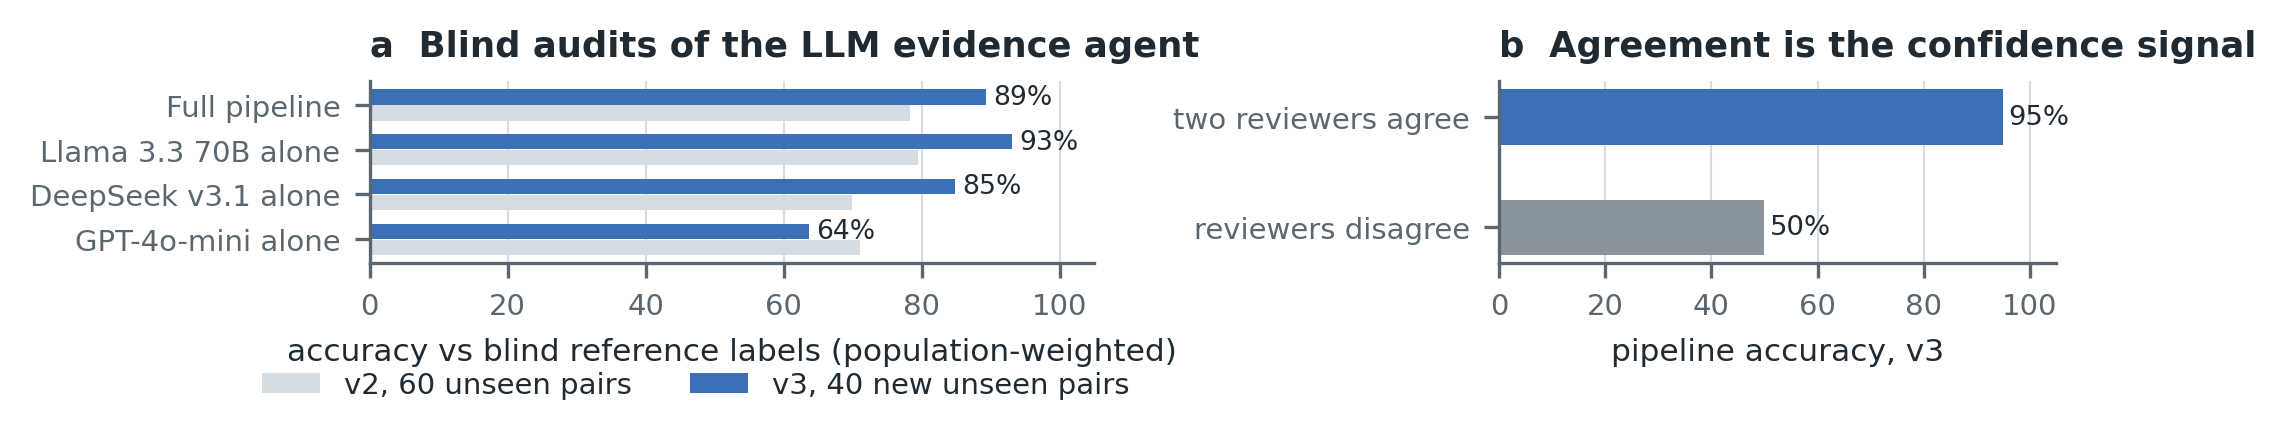

In [11]:
a = summary("09")["audit"]
acc = pd.DataFrame(a["accuracy"]).T[["population_weighted", "agree_stratum", "disagree_stratum", "clear_items_only"]]
display(acc.round(3))
print("held-out pairs:", a["n"], "| reference labels:", a["auditor"])
fig("fig8_agent_audit")

## J. A genetic natural experiment
Colocalization between the UK Biobank baldness GWAS and gene-activity variants (GTEx v8 skin and fibroblasts): does one
causal variant drive both? Reference genes with strong baldness genetics show the method can find a signal.

def labf(beta, se, prior_sd):
    z2 = (beta / se) ** 2
    r = prior_sd ** 2 / (prior_sd ** 2 + se ** 2)
    return 0.5 * np.log(1 - r) + 0.5 * r * z2

def coloc(l1, l2):
    s1, s2, s12 = logsumexp(l1), logsumexp(l2), logsumexp(l1 + l2)
    h3_inner = s1 + s2 + np.log1p(-np.exp(min(s12 - (s1 + s2), -1e-12)))
    lh = np.array([0.0, np.log(P1) + s1, np.log(P2) + s2, np.log(P1) + np.log(P2) + h3_inner, np.log(P12) + s12])
    return np.exp(lh - logsumexp(lh))

hypothesis: 0 of 8 testable gene-tissue pairs share a causal variant
reference: 10 of 23 testable gene-tissue pairs share a causal variant
Fisher p, hypothesis vs reference: 0.032


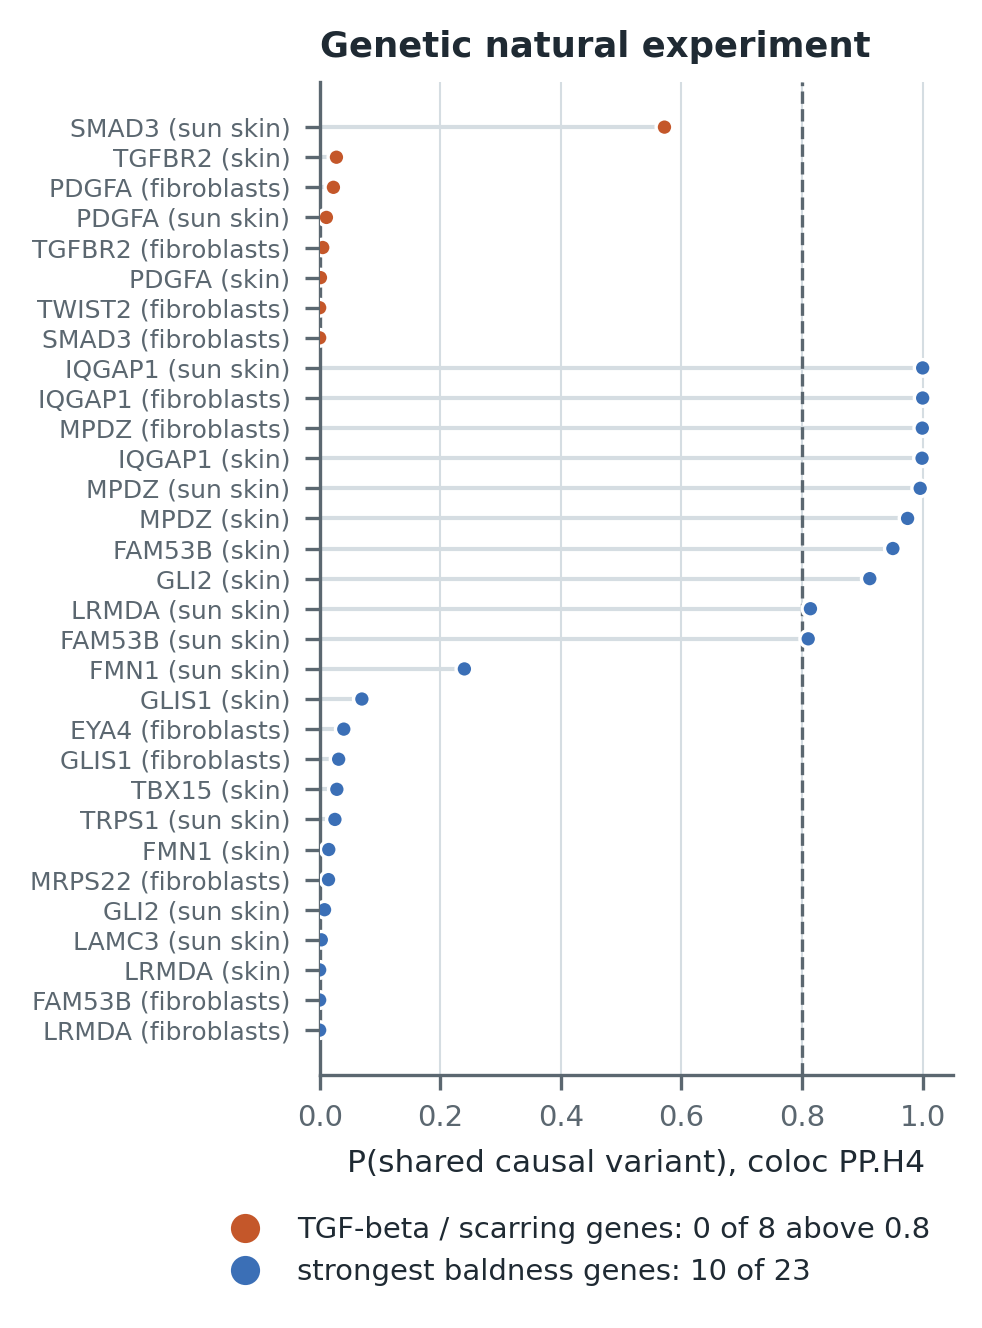

In [12]:
show_code("analysis/10_genetic_natural_experiment.py", ["labf", "coloc"])
p = summary("10")["panels"]
for k in ("hypothesis", "reference"):
    print(f"{k}: {p[k]['shared_variant_H4']} of {p[k]['testable']} testable gene-tissue pairs share a causal variant")
print("Fisher p, hypothesis vs reference:", round(p["fisher_hypothesis_vs_reference"]["p"], 3))
fig("fig7_genetics", 420)

## K and L. The CXCL12 link, and beard vs scalp

In [13]:
c = summary("11")
b, f = c["bald_scalp"]["CXCL12"], c["fibroblast_drugs"]["CXCL12"]
print(f"CXCL12 in bald scalp: consensus z {b['z']:.2f} ({b['z_rank_pct']:.1f}th percentile)")
print(f"Pirfenidone 1 mM: log2 {f['pirf_1mM_lfc']:+.2f} (p {f['pirf_1mM_p']:.4f}); 0.11 mM: {f['pirf_0p1mM_lfc']:+.3f}; nintedanib: {f['nint_lfc']:+.2f}")
print(f"Share of atlas expression in dermal clusters: {c['atlas_share_in_dermal_clusters']['CXCL12']:.0%}")
l = pd.DataFrame(summary("12")["sets"])
display(l[l.gene_set.isin(["TGF-beta-driven bald genes", "Scarring genes up in bald scalp"])][["gene_set", "contrast", "mean_log2_diff", "perm_p_two_sided", "share_of_genes_up"]].round(3))

CXCL12 in bald scalp: consensus z 4.26 (99.0th percentile)
Pirfenidone 1 mM: log2 -1.92 (p 0.0004); 0.11 mM: -0.001; nintedanib: +0.83
Share of atlas expression in dermal clusters: 83%


,gene_set,contrast,mean_log2_diff,perm_p_two_sided,share_of_genes_up
0,TGF-beta-driven bald genes,frontal minus occipital,0.105,0.002,0.739
1,TGF-beta-driven bald genes,beard minus frontal,-0.510,0.000,0.000
2,TGF-beta-driven bald genes,armpit minus frontal,0.743,0.908,0.957
6,Scarring genes up in bald scalp,frontal minus occipital,0.129,0.010,0.750
7,Scarring genes up in bald scalp,beard minus frontal,-0.655,0.000,0.000
8,Scarring genes up in bald scalp,armpit minus frontal,0.432,0.130,0.938


## M and N. The community scan, and dose (**live**: the dose arithmetic reruns here)

YouTube scan (2026-10-04): 17 videos, 2 on pirfenidone; earliest: [{'published': '2026-02-03', 'channel': 'KwRx 🕊️', 'title': 'Hair Loss Reversal From Fibrosis: Topical Pirfenidone'}]



Oral pill, peak blood level: {'fed, capsules': '0.035 mM', 'fed, tablet': '0.041 mM', 'fasted, capsules': '0.067 mM', 'fasted, tablet': '0.068 mM'} | that is 15 to 28x below the 1 mM cell dose
Cell doses: {'no effect (GSE178518, 20 ug/mL)': '0.11 mM', 'reversal (GSE226249)': '1.00 mM'}
Topical on the rabbit eye, peak tissue level at the site: {'conjunctiva': '52 mM', 'cornea': '52 mM', 'sclera': '11 mM'}
Skin gel, liposomal hydrogel, pig ear skin (PMID 26114208): flux 10.9 ug/cm2/h -> whole-dermis average if cleared by blood flow 0.024 to 0.074 mM
Skin gel, 8% nanoemulsion gel, pig skin, 404.9 ug/cm2 over 24 h (PMID 33006045): flux 16.9 ug/cm2/h -> whole-dermis average if cleared by blood flow 0.036 to 0.114 mM
Skin gel, plain pirfenidone, about 5x below the liposomal gel (PMID 26114208): flux 2.2 ug/cm2/h -> whole-dermis average if cleared by blood flow 0.005 to 0.015 mM

Neither route clearly reaches the 1 mM cell-culture level as a whole-dermis average (about 0.01 to 0.1 mM by flux 

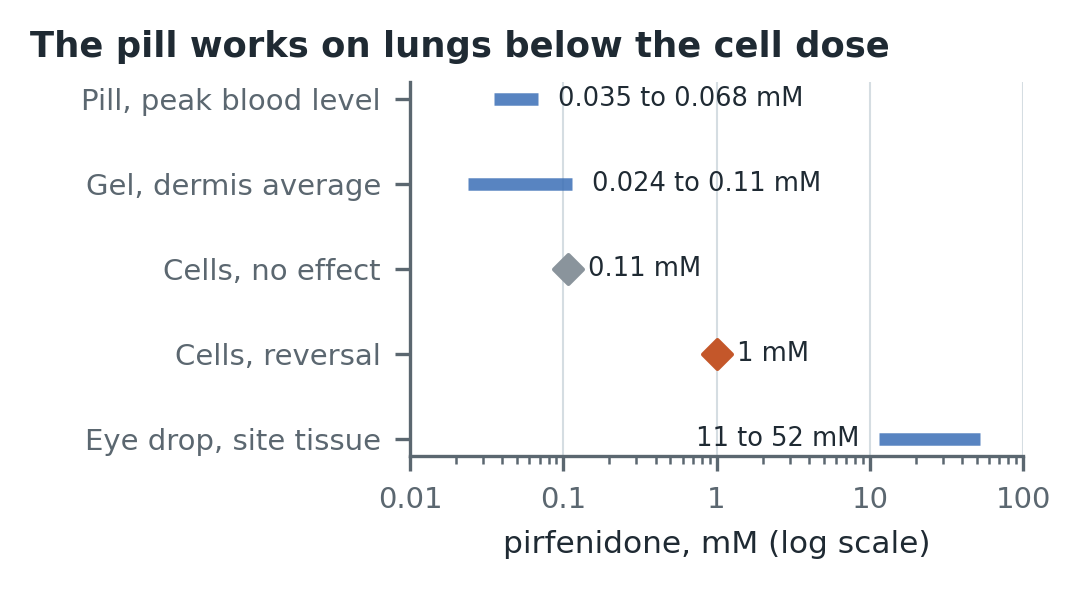

In [14]:
m = summary("13")
print(f"YouTube scan ({m['scanned_on']}): {m['videos']} videos, {m['videos_on_pirfenidone']} on pirfenidone; earliest: {m['earliest_pirfenidone_video']}")
print()
_ = runpy.run_path(str(ROOT / "analysis/14_dose_feasibility.py"), run_name="__main__")
fig("fig9_dose", 520)

## Reproducibility
Fingerprints of every summary file the report quotes. On Oct 4, full rebuilds with `analysis/run_all.sh` reproduced the
summaries for tracks 01 to 12 byte for byte, apart from PubMed counts that drift as new papers are indexed.

In [15]:
rows = [(p.name, hashlib.sha256(p.read_bytes()).hexdigest()[:12]) for p in sorted(RESULTS.glob("*_summary.json"))]
display(pd.DataFrame(rows, columns=["file", "sha256 (first 12)"]))

,file,sha256 (first 12)
0,01_summary.json,a71ca1b6a70e
1,02_summary.json,6c12e371fed8
2,03_summary.json,92e187d8bd8b
3,04_summary.json,7eca8b424bd3
4,05_summary.json,18ed3e4b6a9b
5,06_summary.json,c010c3525335
6,07_summary.json,5613d85a348e
7,08_summary.json,e0fff57d4919
8,09_summary.json,efef02adba6a
9,10_summary.json,86ba86149705
